In [1]:
%pip -q install pandas numpy matplotlib seaborn

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
# Project folders
PROJECT_DIR = Path("/content/P02-air-quality")
RAW_DIR = PROJECT_DIR / "data" / "raw"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in [RAW_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 110

print("Project folders created successfully.")
print("Project location:", PROJECT_DIR)

Project folders created successfully.
Project location: /content/P02-air-quality


In [4]:
from google.colab import files

uploaded = files.upload()

csv_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".csv")
]

if "city_day.csv" in csv_files:
    selected_file = "city_day.csv"
elif len(csv_files) == 1:
    selected_file = csv_files[0]
else:
    raise ValueError(
        "Please upload city_day.csv, or upload exactly one CSV file."
    )

# Save the uploaded dataset in the project's raw data folder.
uploaded_path = RAW_DIR / "city_day.csv"
uploaded_path.write_bytes(uploaded[selected_file])

print("Dataset saved to:", uploaded_path)
print("File size (MB):", round(uploaded_path.stat().st_size / 1e6, 2))

Saving city_day.csv to city_day (2).csv
Dataset saved to: /content/P02-air-quality/data/raw/city_day.csv
File size (MB): 2.57


In [5]:
from google.colab import files

uploaded = files.upload()

csv_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".csv")
]

if "city_day.csv" in csv_files:
    selected_file = "city_day.csv"
elif len(csv_files) == 1:
    selected_file = csv_files[0]
else:
    raise ValueError(
        "Please upload city_day.csv, or upload exactly one CSV file."
    )

# Save the uploaded dataset in the project's raw data folder.
uploaded_path = RAW_DIR / "city_day.csv"
uploaded_path.write_bytes(uploaded[selected_file])

print("Dataset saved to:", uploaded_path)
print("File size (MB):", round(uploaded_path.stat().st_size / 1e6, 2))

Saving city_day.csv to city_day (3).csv
Dataset saved to: /content/P02-air-quality/data/raw/city_day.csv
File size (MB): 2.57


In [6]:
DATA_PATH = RAW_DIR / "city_day.csv"

df = pd.read_csv(DATA_PATH)

if "Date" not in df.columns or "City" not in df.columns:
    raise ValueError("Dataset must contain City and Date columns.")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("Rows and columns:", df.shape)
print("Number of cities:", df["City"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

DATASET OVERVIEW
Rows and columns: (29531, 16)
Number of cities: 26
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00

Column names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Data types:


,Data type
City,object
Date,datetime64[ns]
PM2.5,float64
PM10,float64
NO,float64
NO2,float64
NOx,float64
NH3,float64
CO,float64
SO2,float64



First five rows:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        29531 non-null  object        
 1   Date        29531 non-null  datetime64[ns]
 2   PM2.5       24933 non-null  float64       
 3   PM10        18391 non-null  float64       
 4   NO          25949 non-null  float64       
 5   NO2         25946 non-null  float64       
 6   NOx         25346 non-null  float64       
 7   NH3         19203 non-null  float64       
 8   CO          27472 non-null  float64       
 9   SO2         25677 non-null  float64       
 10  O3          25509 non-null  float64       
 11  Benzene     23908 non-null  float64       
 12  Toluene     21490 non-null  float64       
 13  Xylene      11422 non-null  float64       
 14  AQI         24850 non-null  float64       
 15  AQI_Bucket  24850 non-null  object        
dtype

In [7]:
print("Rows with invalid dates:", df["Date"].isna().sum())
print("Rows with missing city:", df["City"].isna().sum())

print("\nAvailable cities:")
display(
    df["City"]
    .value_counts(dropna=False)
    .rename_axis("City")
    .reset_index(name="Number of rows")
)

# Inspect duplicate city-date records.
valid_key = df.dropna(subset=["City", "Date"])

duplicate_mask = valid_key.duplicated(
    subset=["City", "Date"],
    keep=False
)

duplicate_rows = valid_key.loc[duplicate_mask].sort_values(
    ["City", "Date"]
)

print("\nRows involved in duplicate city-date records:",
      len(duplicate_rows))

display(duplicate_rows.head(20))

Rows with invalid dates: 0
Rows with missing city: 0

Available cities:


,City,Number of rows
0,Ahmedabad,2009
1,Bengaluru,2009
2,Chennai,2009
3,Mumbai,2009
4,Lucknow,2009
5,Delhi,2009
6,Hyderabad,2006
7,Patna,1858
8,Gurugram,1679
9,Visakhapatnam,1462



Rows involved in duplicate city-date records: 0


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket


In [8]:
CITY = "Delhi"

if CITY not in df["City"].dropna().unique():
    raise ValueError(
        f"{CITY} is not present. Check the city names in Cell 5."
    )

city_raw = (
    df.loc[df["City"].eq(CITY)]
    .dropna(subset=["Date"])
    .sort_values("Date")
    .copy()
)

# Enforce one record per date rather than hiding duplicates.
if city_raw["Date"].duplicated().any():
    display(
        city_raw.loc[
            city_raw["Date"].duplicated(keep=False)
        ].sort_values("Date")
    )
    raise ValueError(
        "Duplicate dates found for the selected city. "
        "Investigate these records before continuing."
    )

print("Selected city:", CITY)
print("Original number of observations:", len(city_raw))
print("First observation:", city_raw["Date"].min())
print("Last observation:", city_raw["Date"].max())

display(city_raw.head())

Selected city: Delhi
Original number of observations: 2009
First observation: 2015-01-01 00:00:00
Last observation: 2020-07-01 00:00:00


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
10229,Delhi,2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe
10230,Delhi,2015-01-02,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,454.0,Severe
10231,Delhi,2015-01-03,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,143.0,Moderate
10232,Delhi,2015-01-04,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,319.0,Very Poor
10233,Delhi,2015-01-05,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,325.0,Very Poor


In [9]:
original_dates = pd.DatetimeIndex(city_raw["Date"])

full_calendar = pd.date_range(
    start=original_dates.min(),
    end=original_dates.max(),
    freq="D"
)

missing_dates = full_calendar.difference(original_dates)

print("Expected calendar days:", len(full_calendar))
print("Observed dates:", len(original_dates))
print("Missing calendar dates:", len(missing_dates))

if len(missing_dates) > 0:
    missing_dates_df = pd.DataFrame({
        "Missing date": missing_dates
    })
    missing_dates_df["Year"] = (
        missing_dates_df["Missing date"].dt.year
    )

    display(missing_dates_df.head(20))

    print("\nMissing calendar dates by year:")
    display(
        missing_dates_df.groupby("Year")
        .size()
        .rename("Missing calendar days")
        .reset_index()
    )
else:
    print("No missing calendar dates were found.")

Expected calendar days: 2009
Observed dates: 2009
Missing calendar dates: 0
No missing calendar dates were found.


In [10]:
city_df = (
    city_raw
    .drop(columns=["City"], errors="ignore")
    .set_index("Date")
    .sort_index()
)

if not city_df.index.is_unique:
    raise ValueError("Date index must be unique before reindexing.")

city_df = city_df.reindex(full_calendar)
city_df.index.name = "Date"

# Re-add City as metadata for the selected city.
city_df["City"] = CITY

print("After reindexing:")
print("Number of calendar rows:", len(city_df))
print("Index frequency:", city_df.index.freq)
print("Index is continuous:", city_df.index.is_monotonic_increasing)

display(city_df.head(10))

After reindexing:
Number of calendar rows: 2009
Index frequency: <Day>
Index is continuous: True


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,City
Date,,,,,,,,,,,,,,,
2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe,Delhi
2015-01-02,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,454.0,Severe,Delhi
2015-01-03,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,143.0,Moderate,Delhi
2015-01-04,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,319.0,Very Poor,Delhi
2015-01-05,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,325.0,Very Poor,Delhi
2015-01-06,149.58,252.10,17.21,37.84,42.46,134.97,9.44,3.66,26.83,3.63,7.35,3.47,318.0,Very Poor,Delhi
2015-01-07,217.87,376.51,26.99,40.15,52.41,134.82,9.78,5.82,28.96,4.93,9.42,5.21,353.0,Very Poor,Delhi
2015-01-08,229.90,360.95,23.34,43.16,51.21,138.13,11.01,3.31,30.51,5.80,11.40,4.83,383.0,Very Poor,Delhi
2015-01-09,201.66,397.43,19.18,38.56,45.60,140.60,11.09,3.48,32.94,5.25,11.12,5.26,375.0,Very Poor,Delhi


In [11]:
pollutant_columns = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene",
    "Xylene", "AQI"
]

for col in pollutant_columns:
    if col in city_df.columns:
        city_df[col] = pd.to_numeric(
            city_df[col],
            errors="coerce"
        )

if "AQI_Bucket" in city_df.columns:
    city_df["AQI_Bucket"] = (
        city_df["AQI_Bucket"].astype("string")
    )

print("Data types after conversion:")
display(city_df.dtypes.to_frame("Data type"))

print("\nNumerical summary:")
display(city_df.select_dtypes(include="number").describe().T)

Data types after conversion:


,Data type
PM2.5,float64
PM10,float64
NO,float64
NO2,float64
NOx,float64
NH3,float64
CO,float64
SO2,float64
O3,float64
Benzene,float64



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
PM2.5,2007.0,117.196153,82.912945,10.24,57.0950,94.62,153.0300,685.36
PM10,1932.0,232.809229,121.873025,18.59,137.0400,216.73,311.6675,796.88
NO,2007.0,38.985595,33.389456,3.57,15.8950,27.20,50.7900,221.03
NO2,2007.0,50.785182,22.696721,10.63,33.8950,47.15,63.5700,162.50
NOx,2009.0,58.567023,37.690350,0.00,31.1500,52.75,75.3600,254.80
NH3,2000.0,41.997150,17.301221,6.78,31.1575,38.04,48.7925,166.70
CO,2009.0,1.976053,2.560253,0.00,0.9100,1.24,1.8700,30.44
SO2,1899.0,15.901253,7.966770,2.34,10.3350,14.45,19.7000,71.56
O3,1925.0,51.323610,26.062340,6.94,33.7100,44.44,60.8400,257.73
Benzene,2009.0,3.544480,2.431232,0.00,1.8700,2.96,4.6800,20.64


In [12]:
analysis_columns = [
    col for col in city_df.columns
    if col != "City"
]

missingness_records = []

for year, yearly_data in city_df.groupby(city_df.index.year):
    for col in analysis_columns:
        missing_count = int(yearly_data[col].isna().sum())
        total_count = len(yearly_data)

        missingness_records.append({
            "City": CITY,
            "Year": int(year),
            "Column": col,
            "Total calendar days": total_count,
            "Missing days": missing_count,
            "Missing percentage": (
                100 * missing_count / total_count
                if total_count else np.nan
            )
        })

missingness_long = pd.DataFrame(missingness_records)

missingness_long["Missing percentage"] = (
    missingness_long["Missing percentage"].round(2)
)

print("Missingness by year and column:")
display(
    missingness_long.pivot(
        index="Column",
        columns="Year",
        values="Missing percentage"
    )
)

missingness_long.to_csv(
    RESULTS_DIR / "missingness_by_year.csv",
    index=False
)

print("Saved:", RESULTS_DIR / "missingness_by_year.csv")

Missingness by year and column:


Year,2015,2016,2017,2018,2019,2020
Column,,,,,,
AQI,0.00,0.27,2.47,0.0,0.0,0.0
AQI_Bucket,0.00,0.27,2.47,0.0,0.0,0.0
Benzene,0.00,0.00,0.00,0.0,0.0,0.0
CO,0.00,0.00,0.00,0.0,0.0,0.0
NH3,0.00,1.37,1.10,0.0,0.0,0.0
NO,0.00,0.00,0.55,0.0,0.0,0.0
NO2,0.00,0.00,0.55,0.0,0.0,0.0
NOx,0.00,0.00,0.00,0.0,0.0,0.0
O3,0.00,0.00,23.01,0.0,0.0,0.0


Saved: /content/P02-air-quality/results/missingness_by_year.csv


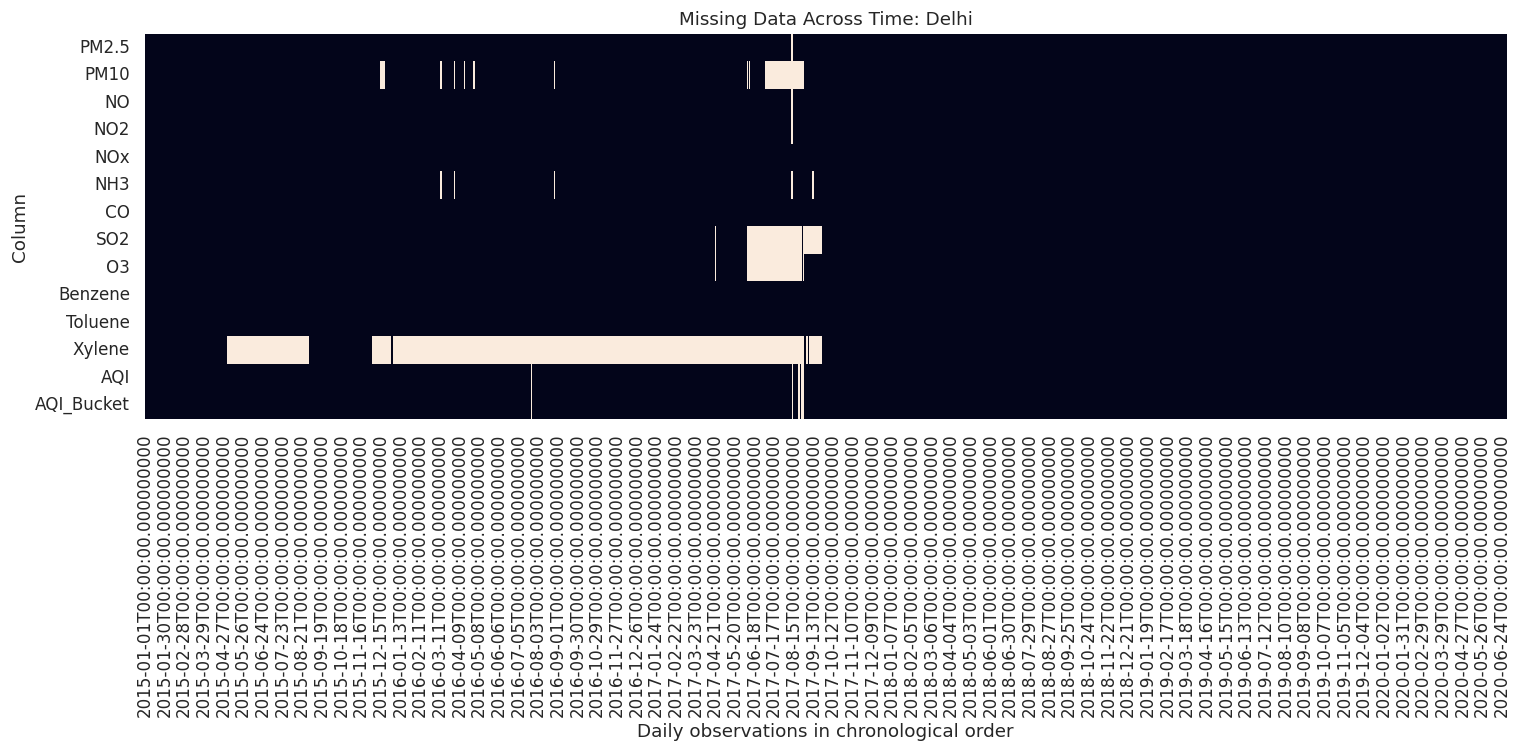

In [13]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    city_df[analysis_columns].isna().T,
    cbar=False,
    yticklabels=True
)

plt.title(f"Missing Data Across Time: {CITY}")
plt.xlabel("Daily observations in chronological order")
plt.ylabel("Column")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "missingness_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

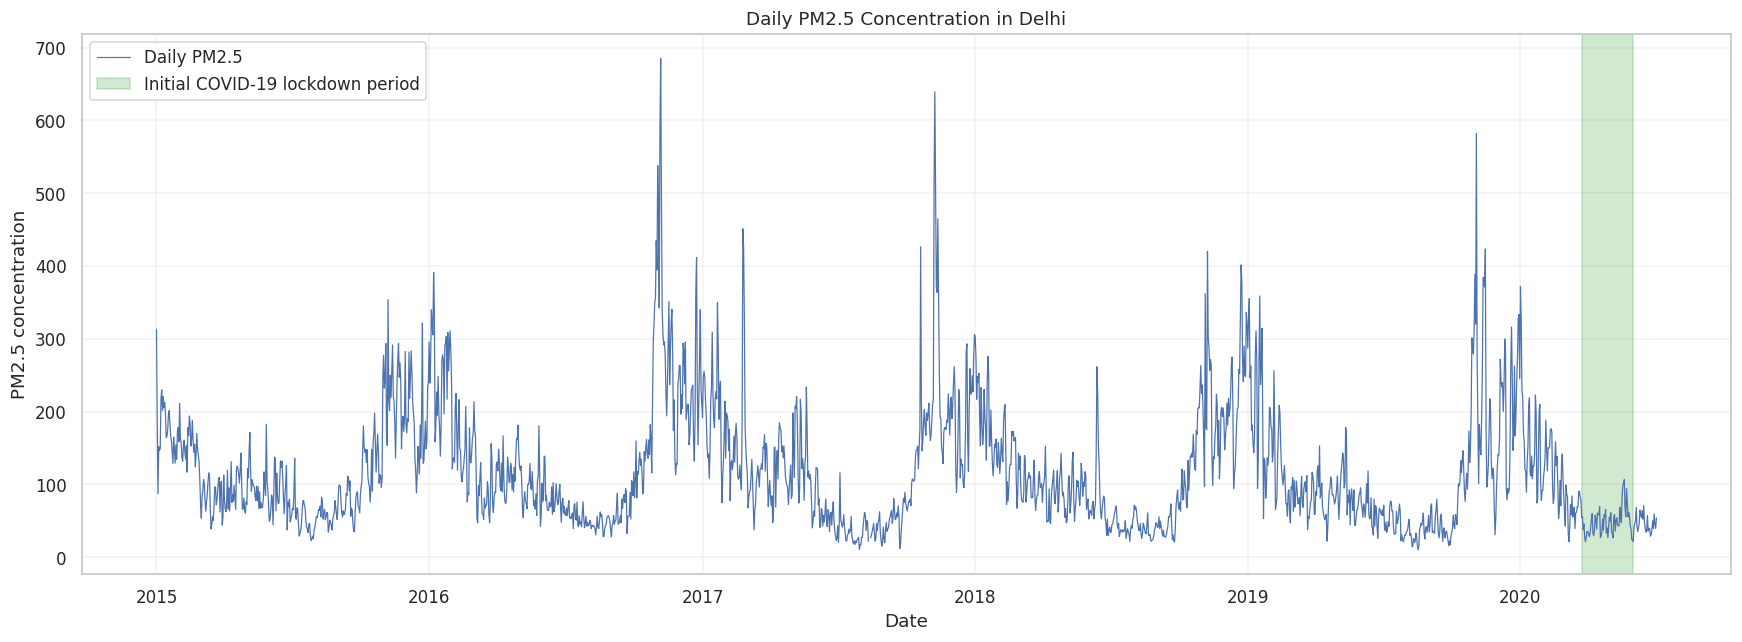

In [14]:
if "PM2.5" not in city_df.columns:
    raise ValueError("PM2.5 column not found.")

plt.figure(figsize=(16, 6))

plt.plot(
    city_df.index,
    city_df["PM2.5"],
    linewidth=0.8,
    label="Daily PM2.5"
)

# Highlight India's initial nationwide lockdown period.
plt.axvspan(
    pd.Timestamp("2020-03-24"),
    pd.Timestamp("2020-05-31"),
    alpha=0.18,
    color="green",
    label="Initial COVID-19 lockdown period"
)

plt.title(f"Daily PM2.5 Concentration in {CITY}")
plt.xlabel("Date")
plt.ylabel("PM2.5 concentration")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "pm25_over_time.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

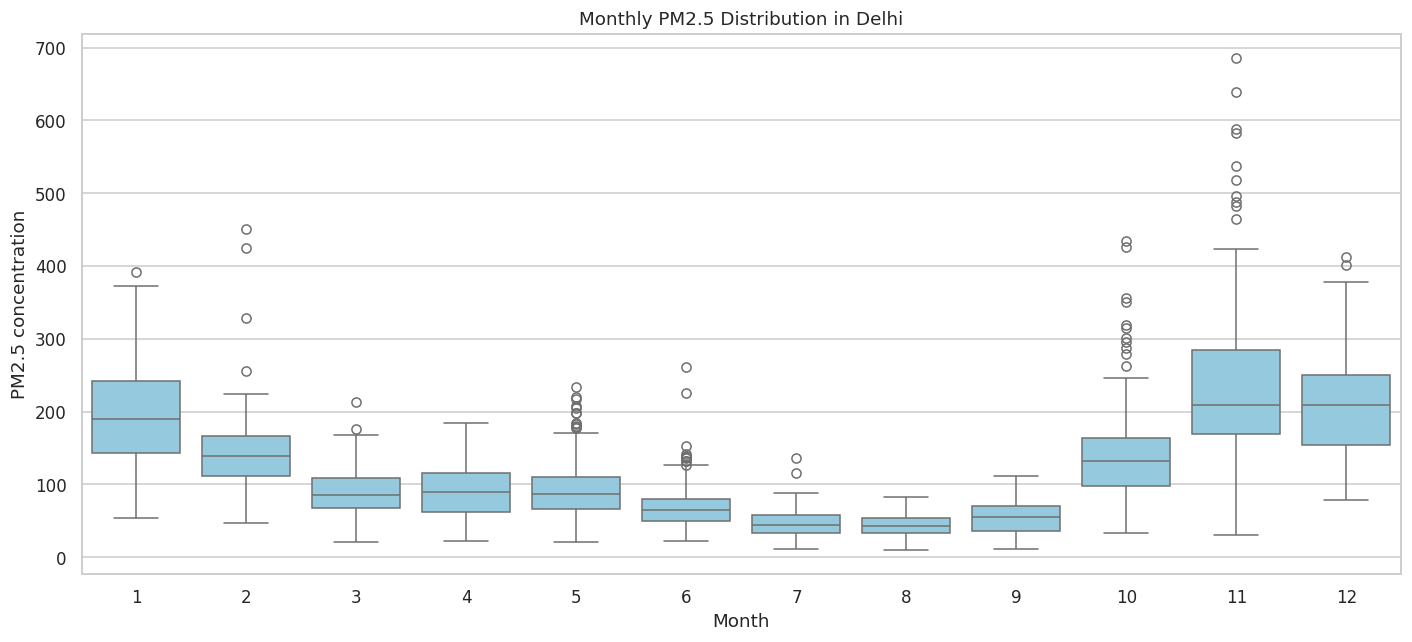

In [15]:
monthly_data = city_df[["PM2.5"]].copy()

monthly_data["Month"] = monthly_data.index.month
monthly_data["Year"] = monthly_data.index.year

monthly_data = monthly_data.dropna(subset=["PM2.5"])

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=monthly_data,
    x="Month",
    y="PM2.5",
    color="skyblue"
)

plt.title(f"Monthly PM2.5 Distribution in {CITY}")
plt.xlabel("Month")
plt.ylabel("PM2.5 concentration")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "pm25_monthly_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [16]:
if "PM2.5" in city_df.columns:
    pm25 = city_df["PM2.5"]

    print("PM2.5 summary")
    print("-" * 40)
    print("Available measurements:", int(pm25.notna().sum()))
    print("Missing measurements:", int(pm25.isna().sum()))
    print("Mean:", round(pm25.mean(), 2))
    print("Median:", round(pm25.median(), 2))
    print("Standard deviation:", round(pm25.std(), 2))
    print("Minimum:", round(pm25.min(), 2))
    print("Maximum:", round(pm25.max(), 2))

    print(
        "Percentage of days with missing PM2.5:",
        round(pm25.isna().mean() * 100, 2),
        "%"
    )

PM2.5 summary
----------------------------------------
Available measurements: 2007
Missing measurements: 2
Mean: 117.2
Median: 94.62
Standard deviation: 82.91
Minimum: 10.24
Maximum: 685.36
Percentage of days with missing PM2.5: 0.1 %


In [17]:
policy_text = f"""
# P02 Air Quality: Missing-Data Policy

## Selected city
{CITY}

## Phase A findings
The dataset was reindexed to a continuous daily calendar.
The missingness tables distinguish the complete calendar from
the original observed records.

See:
- results/missingness_by_year.csv
- results/missingness_observed_rows.csv
- results/figures/missingness_heatmap.png

## Provisional policy for later modelling

1. Target values:
   - Do not impute missing PM2.5 target values.
   - Do not impute missing AQI_Bucket target labels.
   - Exclude samples whose required target is unknown.

2. Predictor columns:
   - Investigate the missingness of each predictor using the
     per-year tables and the training period.
   - Consider excluding a predictor if more than 40% of its
     values are missing in the training period, or if an
     entire year has no usable measurements.
   - Justify each exclusion using actual missingness results.

3. Remaining predictor values:
   - Start with median imputation for numeric predictors.
   - Fit imputers on training data only, preferably inside a
     scikit-learn pipeline.
   - Do not fit preprocessing on the complete dataset.

4. Calendar gaps:
   - Retain a continuous daily index.
   - Do not treat a previous available row as yesterday unless
     it is actually the previous calendar day.
   - Do not forward-fill long gaps automatically.

5. Evaluation:
   - Use time-ordered splits.
   - Apply the same test dates when comparing models and the
     persistence baseline.
   - Report the amount of data excluded by preprocessing.

## Finalisation
Review the missingness tables before confirming which
predictors to retain or drop. Update this policy with the
actual column names and observed percentages.
"""

policy_path = RESULTS_DIR / "missing_data_policy.md"
policy_path.write_text(policy_text, encoding="utf-8")

display(Markdown(policy_text))
print("Saved:", policy_path)


# P02 Air Quality: Missing-Data Policy

## Selected city
Delhi

## Phase A findings
The dataset was reindexed to a continuous daily calendar.
The missingness tables distinguish the complete calendar from
the original observed records.

See:
- results/missingness_by_year.csv
- results/missingness_observed_rows.csv
- results/figures/missingness_heatmap.png

## Provisional policy for later modelling

1. Target values:
   - Do not impute missing PM2.5 target values.
   - Do not impute missing AQI_Bucket target labels.
   - Exclude samples whose required target is unknown.

2. Predictor columns:
   - Investigate the missingness of each predictor using the
     per-year tables and the training period.
   - Consider excluding a predictor if more than 40% of its
     values are missing in the training period, or if an
     entire year has no usable measurements.
   - Justify each exclusion using actual missingness results.

3. Remaining predictor values:
   - Start with median imputation for numeric predictors.
   - Fit imputers on training data only, preferably inside a
     scikit-learn pipeline.
   - Do not fit preprocessing on the complete dataset.

4. Calendar gaps:
   - Retain a continuous daily index.
   - Do not treat a previous available row as yesterday unless
     it is actually the previous calendar day.
   - Do not forward-fill long gaps automatically.

5. Evaluation:
   - Use time-ordered splits.
   - Apply the same test dates when comparing models and the
     persistence baseline.
   - Report the amount of data excluded by preprocessing.

## Finalisation
Review the missingness tables before confirming which
predictors to retain or drop. Update this policy with the
actual column names and observed percentages.


Saved: /content/P02-air-quality/results/missing_data_policy.md


In [18]:
eda_output_path = RESULTS_DIR / f"{CITY.lower()}_daily_reindexed.csv"

city_df.to_csv(eda_output_path, index_label="Date")

print("Saved EDA dataset:", eda_output_path)
print("Original raw data remains unchanged:", DATA_PATH.exists())

Saved EDA dataset: /content/P02-air-quality/results/delhi_daily_reindexed.csv
Original raw data remains unchanged: True


In [19]:
years = sorted(city_df.index.year.unique())

summary = {
    "Selected city": CITY,
    "First calendar date": str(city_df.index.min().date()),
    "Last calendar date": str(city_df.index.max().date()),
    "Calendar days": len(city_df),
    "Observed city-date rows": len(city_raw),
    "Missing calendar dates before reindexing": len(missing_dates),
    "Available PM2.5 observations": int(city_df["PM2.5"].notna().sum()),
    "Missing PM2.5 values after reindexing": int(city_df["PM2.5"].isna().sum()),
    "PM2.5 missing percentage": round(
        city_df["PM2.5"].isna().mean() * 100, 2
    ),
    "Years covered": ", ".join(map(str, years))
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Measure", "Value"]
)

display(summary_df)

summary_df.to_csv(
    RESULTS_DIR / "eda_summary.csv",
    index=False
)

,Measure,Value
0,Selected city,Delhi
1,First calendar date,2015-01-01
2,Last calendar date,2020-07-01
3,Calendar days,2009
4,Observed city-date rows,2009
5,Missing calendar dates before reindexing,0
6,Available PM2.5 observations,2007
7,Missing PM2.5 values after reindexing,2
8,PM2.5 missing percentage,0.1
9,Years covered,"2015, 2016, 2017, 2018, 2019, 2020"


In [20]:
report_template = f"""
# P02: Next-Day Air Quality for an Indian City

## 1. Objective
The project investigates whether historical pollutant readings
and calendar information can predict next-day PM2.5 concentration
and next-day AQI category.

## 2. City selection
Selected city: {CITY}

Justification:
The project brief identifies Delhi as a useful starting city
because of its broad pollution range and comparatively complete
record. This choice must be checked against the observed
missingness and date coverage.

## 3. Dataset
Source:
https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india

File: city_day.csv

The dataset contains city-level daily pollution measurements
and AQI information.

## 4. Data quality
Describe:
- Date coverage
- Missing calendar dates
- Duplicate city-date records
- Missingness by column and year
- Features with extensive or long-duration gaps

See results/missingness_by_year.csv.

## 5. Missing-data policy
Explain the decisions in results/missing_data_policy.md.
Revise the provisional policy after reviewing the actual
missingness statistics.

## 6. PM2.5 trends
Discuss the observed time-series plot and monthly distribution.
Investigate winter spikes and the 2020 lockdown period.
Do not claim a pattern that is not visible in the data.

## 7. Limitations
Discuss missing measurements, monitoring coverage, possible
sensor issues and the limitations of a single-city dataset.

## 8. Next steps
Build the persistence baseline and first time-ordered linear
regression model in Phase B.
"""

report_path = RESULTS_DIR / "phase_a_report_template.md"
report_path.write_text(report_template, encoding="utf-8")

print("Report template saved:", report_path)
display(Markdown(report_template))

Report template saved: /content/P02-air-quality/results/phase_a_report_template.md



# P02: Next-Day Air Quality for an Indian City

## 1. Objective
The project investigates whether historical pollutant readings
and calendar information can predict next-day PM2.5 concentration
and next-day AQI category.

## 2. City selection
Selected city: Delhi

Justification:
The project brief identifies Delhi as a useful starting city
because of its broad pollution range and comparatively complete
record. This choice must be checked against the observed
missingness and date coverage.

## 3. Dataset
Source:
https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india

File: city_day.csv

The dataset contains city-level daily pollution measurements
and AQI information.

## 4. Data quality
Describe:
- Date coverage
- Missing calendar dates
- Duplicate city-date records
- Missingness by column and year
- Features with extensive or long-duration gaps

See results/missingness_by_year.csv.

## 5. Missing-data policy
Explain the decisions in results/missing_data_policy.md.
Revise the provisional policy after reviewing the actual
missingness statistics.

## 6. PM2.5 trends
Discuss the observed time-series plot and monthly distribution.
Investigate winter spikes and the 2020 lockdown period.
Do not claim a pattern that is not visible in the data.

## 7. Limitations
Discuss missing measurements, monitoring coverage, possible
sensor issues and the limitations of a single-city dataset.

## 8. Next steps
Build the persistence baseline and first time-ordered linear
regression model in Phase B.


In [21]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/P02_phaseA",
    "zip",
    root_dir="/content",
    base_dir="P02-air-quality"
)

print("Phase A files packaged successfully.")
print("ZIP location:", zip_path)

files.download(zip_path)

Phase A files packaged successfully.
ZIP location: /content/P02_phaseA.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:

obs_records = []
for col in analysis_columns:
    missing_count = int(city_raw[col].isna().sum())
    total_count = len(city_raw)
    obs_records.append({
        "City": CITY,
        "Column": col,
        "Total observed rows": total_count,
        "Missing rows": missing_count,
        "Missing percentage": round(100 * missing_count / total_count, 2) if total_count else 0
    })

obs_df = pd.DataFrame(obs_records)
obs_df.to_csv(PROJECT_DIR / "results" / "missingness_observed_rows.csv", index=False)
print("Saved missingness_observed_rows.csv successfully.")

Saved missingness_observed_rows.csv successfully.


In [23]:
from IPython.display import display, Markdown

missingness = pd.read_csv(
    PROJECT_DIR / "results" / "missingness_by_year.csv"
)

display(Markdown("## Missing values by year"))
display(missingness)

observed_missingness = pd.read_csv(
    PROJECT_DIR / "results" / "missingness_observed_rows.csv"
)

display(Markdown("## Missing values in originally observed rows"))
display(observed_missingness)

## Missing values by year

,City,Year,Column,Total calendar days,Missing days,Missing percentage
0,Delhi,2015,PM2.5,365,0,0.00
1,Delhi,2015,PM10,365,7,1.92
2,Delhi,2015,NO,365,0,0.00
3,Delhi,2015,NO2,365,0,0.00
4,Delhi,2015,NOx,365,0,0.00
...,...,...,...,...,...,...
79,Delhi,2020,Benzene,183,0,0.00
80,Delhi,2020,Toluene,183,0,0.00
81,Delhi,2020,Xylene,183,0,0.00
82,Delhi,2020,AQI,183,0,0.00


## Missing values in originally observed rows

,City,Column,Total observed rows,Missing rows,Missing percentage
0,Delhi,PM2.5,2009,2,0.10
1,Delhi,PM10,2009,77,3.83
2,Delhi,NO,2009,2,0.10
3,Delhi,NO2,2009,2,0.10
4,Delhi,NOx,2009,0,0.00
5,Delhi,NH3,2009,9,0.45
6,Delhi,CO,2009,0,0.00
7,Delhi,SO2,2009,110,5.48
8,Delhi,O3,2009,84,4.18
9,Delhi,Benzene,2009,0,0.00


In [24]:
policy_path = PROJECT_DIR / "results" / "missing_data_policy.md"
print(policy_path.read_text())



# P02 Air Quality: Missing-Data Policy

## Selected city
Delhi

## Phase A findings
The dataset was reindexed to a continuous daily calendar.
The missingness tables distinguish the complete calendar from
the original observed records.

See:
- results/missingness_by_year.csv
- results/missingness_observed_rows.csv
- results/figures/missingness_heatmap.png

## Provisional policy for later modelling

1. Target values:
   - Do not impute missing PM2.5 target values.
   - Do not impute missing AQI_Bucket target labels.
   - Exclude samples whose required target is unknown.

2. Predictor columns:
   - Investigate the missingness of each predictor using the
     per-year tables and the training period.
   - Consider excluding a predictor if more than 40% of its
     values are missing in the training period, or if an
     entire year has no usable measurements.
   - Justify each exclusion using actual missingness results.

3. Remaining predictor values:
   - Start with median imputation for 

# Missing-Data Policy

## Dataset and Calendar

The analysis uses Delhi air-quality data covering the period from 2015 to 2020. The dates were reindexed to a continuous daily calendar so that lag and rolling-window features correspond to actual calendar days.

## Missingness Findings

- **Columns with the highest missingness:** Xylene had the highest missingness, with 781 missing days out of 2,009 calendar days across the selected period, representing approximately 38.88%. The next highest were SO2 (5.48%), O3 (4.18%), and PM10 (3.83%).
- **Year with the greatest missingness:** 2017 had the highest overall missingness, with 547 missing values across the pollutant and air-quality columns, followed by 2016 with 381 and 2015 with 159. These counts represent missing column values, not unique missing calendar dates.
- **PM2.5 missingness:** PM2.5 had only 2 missing values across the selected period, representing approximately 0.10% of the 2,009 calendar days. Both missing values occurred in 2017, which had 2 missing days out of 365 (0.55%). No PM2.5 missing values were reported for the other years in the provided summary.
- **Missing calendar dates:** The dataset was reindexed to a continuous daily calendar to identify dates absent from the original records. The total number of unique missing calendar dates should be reported using the date-reindexing results from the analysis notebook, since the annual missingness summary does not establish that count.

## Handling Missing Values

1. Rows without the required target value will be excluded from the corresponding training or evaluation dataset.
2. Missing predictor values will be imputed using a median imputer fitted on the training data only.
3. Predictors with extensive missingness will be reviewed before inclusion. Any dropped predictors and the reasons for dropping them will be documented. Xylene requires particular attention because approximately 38.88% of its values are missing.
4. Long gaps will not be filled automatically using forward-fill without justification.
5. Data splitting will follow chronological order. Imputation and other learned preprocessing steps will be fitted on training data only to avoid data leakage.

## Limitations

Missingness may reduce the amount of usable training data and may not be random. Imputation can introduce errors, especially during abrupt changes in pollution levels. Predictors with extensive missingness may provide unreliable information if their missing values are systematically related to particular periods or pollution conditions. These limitations will be considered when selecting features and evaluating model performance.

In [25]:
required_files = [
    PROJECT_DIR / "results" / "missingness_by_year.csv",
    PROJECT_DIR / "results" / "missingness_observed_rows.csv",
    PROJECT_DIR / "results" / "missing_data_policy.md",
    PROJECT_DIR / "results" / "delhi_daily_reindexed.csv",
    PROJECT_DIR / "results" / "figures" / "missingness_heatmap.png",
    PROJECT_DIR / "results" / "figures" / "pm25_over_time.png",
    PROJECT_DIR / "results" / "figures" / "pm25_monthly_distribution.png",
]

for path in required_files:
    print(("yes" if path.exists() else "no"), path.name)

yes missingness_by_year.csv
yes missingness_observed_rows.csv
yes missing_data_policy.md
yes delhi_daily_reindexed.csv
yes missingness_heatmap.png
yes pm25_over_time.png
yes pm25_monthly_distribution.png
